# Vectorizers × classifiers

We compare three text representations with logistic regression, LightGBM boosted trees,
and a neural classifier. Each classifier also receives the same structural features:
lengths, formatting, refusal indicators, empty responses, and pairwise differences.

TF-IDF represents lexical evidence. A randomly initialized GRU learns from the
competition training texts and preference labels, then supplies frozen vectors.
Qwen3-Embedding-8B supplies pretrained semantic vectors through the approved Eliza API.


In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
candidates = [Path.cwd().resolve(), Path.cwd().resolve().parent, Path.home()/'prj/llm_classification_finetuning']
REPO = next(p for p in candidates if (p/'src/arena').is_dir() and (p/'results/attempt_001').is_dir())
sys.path.insert(0, str(REPO / 'src'))
from arena.data import ROOT, CLASSES, TEXT_COLUMNS
RESULTS = REPO / 'results/attempt_001'
ARTIFACTS = ROOT / 'runs/attempt_001'
FIGURES = ROOT / 'reports/attempt_001'
FIGURES.mkdir(parents=True, exist_ok=True)
summary = json.loads((RESULTS / 'data_summary.json').read_text())
evaluation = json.loads((RESULTS / 'metrics.json').read_text()) if (RESULTS/'metrics.json').exists() else None
comparison = pd.read_json(RESULTS / 'comparison.json').sort_values('dev_log_loss') if (RESULTS/'comparison.json').exists() else None
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False})


In [2]:
tfidf = json.loads((RESULTS/'tfidf_metadata.json').read_text())
rnn = json.loads((RESULTS/'rnn_metadata.json').read_text())
qwen = json.loads((RESULTS/'qwen_metadata.json').read_text())
display(pd.Series(tfidf, name='TF-IDF + SVD'))
display(pd.Series({k:v for k,v in rnn.items() if k != 'diagnostics'}, name='GRU'))
display(pd.DataFrame(rnn['diagnostics']).T)
display(pd.Series(qwen, name='Qwen3'))

vocabulary               40000
dimensions                  96
explained_variance    0.111084
fit_partition            train
ngram_range             [1, 2]
Name: TF-IDF + SVD, dtype: object

vocabulary_size                30000
max_tokens                       128
hidden                            48
embedding_dimension               96
best_dev_log_loss           1.027811
epochs_run                         6
fit_partition                  train
early_stopping_partition         dev
Name: GRU, dtype: object

,truncation_rate,unknown_token_rate
prompt,0.120529,0.032313
response_a,0.646625,0.025989
response_b,0.650157,0.025907


model                                                   qwen/qwen3-embedding-8b
dimensions                                                                  256
unique_texts                                                             164416
total_texts                                                              172440
sha256                        fc6f2aff22503d53e37c8b9eed842721e707c4c5992d38...
batch_size                                                                   32
max_chars                                                                  6000
truncated_occurrences                                                      1971
endpoint                      https://api.eliza.yandex.net/raw/openrouter/v1...
created_with                                                  clip-head-tail-v1
completed_batches                                                          5138
api_reported_prompt_tokens                                             36532532
api_reported_cost                       

## Recurrent training and checkpoint selection

The shared GRU reads each field with 128-token head/tail truncation. Its vector
combines masked mean pooling and the final recurrent state. Training uses dropout,
gradient clipping, AdamW, label smoothing, random A/B swapping, and development early
stopping. The best checkpoint is restored before extracting all vectors.

The curve below distinguishes learning on training data from generalization.
These results establish the quality achieved by this attempt; they do not imply
that a small GRU matches a pretrained language model's understanding.


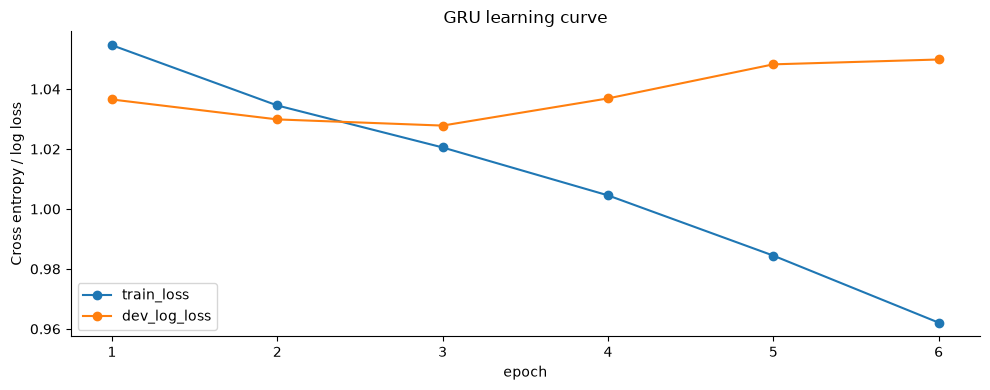

,epoch,train_loss,dev_log_loss,seconds
0,1,1.05462,1.03652,49.60074
1,2,1.03452,1.02987,50.34690
2,3,1.02052,1.02781,56.73989
3,4,1.00454,1.03687,54.64762
4,5,0.98444,1.04824,53.17889
5,6,0.96209,1.04985,51.97043


In [3]:
history = pd.read_json(RESULTS/'rnn_history.json')
ax = history.plot(x='epoch', y=['train_loss','dev_log_loss'], marker='o')
ax.set(ylabel='Cross entropy / log loss', title='GRU learning curve')
plt.tight_layout(); plt.savefig(FIGURES/'rnn_learning.svg'); plt.show()
display(history.round(5))

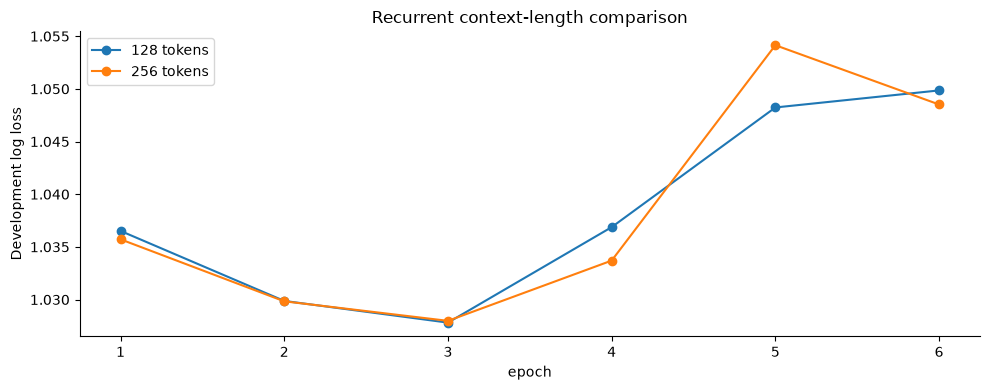

,epoch,train_loss,dev_log_loss,seconds
0,1,1.05485,1.03572,134.99502
1,2,1.03417,1.02983,148.18192
2,3,1.01920,1.02798,145.19865
3,4,1.00412,1.03370,139.65721
4,5,0.98214,1.05415,172.12355
5,6,0.95934,1.04852,170.05659


In [4]:
long_history_path = RESULTS/'rnn_long_history.json'
if long_history_path.exists():
    long_history = pd.read_json(long_history_path)
    ax = history.plot(x='epoch', y='dev_log_loss', marker='o', label='128 tokens')
    long_history.plot(x='epoch', y='dev_log_loss', marker='o', label='256 tokens', ax=ax)
    ax.set(ylabel='Development log loss', title='Recurrent context-length comparison')
    plt.tight_layout(); plt.savefig(FIGURES/'rnn_context_comparison.svg'); plt.show()
    display(long_history.round(5))

## Development comparison

For the dense TF-IDF comparison, SVD is fitted only on training texts. We also retain
a direct sparse TF-IDF logistic baseline to measure the cost of this reduction.
The neural classifier uses a 128-unit hidden layer, dropout, weight decay and early
stopping. All models augment response swaps and average both orientations at inference.
The direct recurrent head is an extra baseline, separate from classifiers on frozen
recurrent vectors.


classifier,gbdt,logistic,neural
representation,,,
qwen3_256,1.01717,1.03760,1.02586
rnn,1.02945,1.05701,1.04322
tfidf_svd,1.02263,1.03817,1.02791


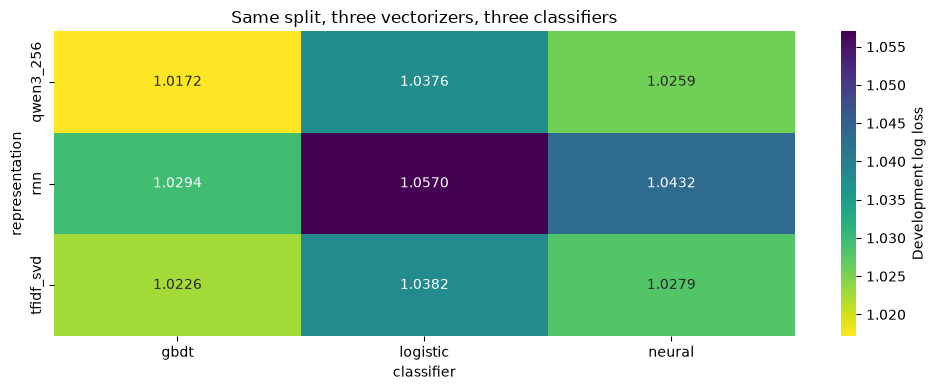

In [5]:
rows = evaluation['models']
table = pd.DataFrame([{'representation':r['representation'], 'classifier':r['classifier'], 'dev_log_loss':r['dev']['log_loss']} for r in rows])
matrix = table[table.representation.isin(['tfidf_svd','rnn','qwen3_256']) & table.classifier.isin(['logistic','gbdt','neural'])].pivot(index='representation', columns='classifier', values='dev_log_loss')
display(matrix.round(5))
import seaborn as sns
sns.heatmap(matrix, annot=True, fmt='.4f', cmap='viridis_r', cbar_kws={'label':'Development log loss'})
plt.title('Same split, three vectorizers, three classifiers'); plt.tight_layout(); plt.savefig(FIGURES/'vectorizers_classifiers.svg'); plt.show()

## API extraction and context limits

The Eliza integration follows the earlier local session's embedding route and reads
credentials locally; credentials never enter notebooks. Extraction deduplicates texts,
uses resumable cached batches and requests 256-dimensional vectors. Texts longer than
6,000 characters use a fixed head/tail rule. No labels enter the pretrained embedder.
[Qwen's model card](https://huggingface.co/Qwen/Qwen3-Embedding-8B) documents support
for reduced embedding dimensions.

The remote embedding results are research results. A Kaggle notebook with internet
disabled needs a bundled, publicly available local checkpoint for this representation.


## Reproduce training

Training stays in source modules to make the long computations reusable from a notebook
or the command line. Enable the switch below only when intentionally rerunning the
experiment. Running remote extraction sends the full dataset text to Eliza and requires
an appropriate local credential.


In [6]:
RUN_TRAINING = False
if RUN_TRAINING:
    import subprocess
    for stage in ['structural','tfidf','rnn','rnn_long']:
        subprocess.run([sys.executable, str(REPO/'scripts/run_experiments.py'), stage], check=True, cwd=REPO)
    subprocess.run([sys.executable, str(REPO/'scripts/refine_tfidf.py')], check=True, cwd=REPO)
    # Remote extraction, approved for this project:
    # subprocess.run([sys.executable, str(REPO/'scripts/embed.py')], check=True, cwd=REPO)
    # Then run stages 'qwen' and 'hybrid'.